In [1]:
import os
import time
from datetime import timedelta
from pathlib import Path

import numpy as np
from gvxrPython3 import gvxr
from gvxrPython3.utils import visualise
from matplotlib import pyplot as plt

import common

In [2]:
gvxr.useLogFile()

In [3]:
backend = "EGL"
gvxr.createNewContext(backend)

error: XDG_RUNTIME_DIR is invalid or not set in the environment.
error: XDG_RUNTIME_DIR is invalid or not set in the environment.


In [4]:
data_dir = common.data_dir
print(f"{data_dir=}")

rope_dir = data_dir / "rope"

data_dir=PosixPath('/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data')


In [5]:
voxel_size_mm = 0.1  # physical size of one qim3d voxel

scene_object_ids = []
for mesh_path in sorted(rope_dir.glob("*.stl")):
    print(mesh_path, mesh_path.stat().st_size, flush=True)

    object_id = mesh_path.stem

    gvxr.loadMeshFile(object_id, str(mesh_path), "mm")
    gvxr.scaleNode(object_id, voxel_size_mm, voxel_size_mm, voxel_size_mm)
    gvxr.rotateNode(object_id, 90, 0, 1, 0)  # rope length (x) -> z = rotation axis
    gvxr.applyCurrentLocalTransformation(
        object_id
    )  # bake scale + rotation into the vertices

    scene_object_ids.append(object_id)


/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data/rope/input_fibre_1.stl 1179684
/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data/rope/input_fibre_10.stl 1928284
/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data/rope/input_fibre_11.stl 1891884
/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data/rope/input_fibre_12.stl 1896084
/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data/rope/input_fibre_13.stl 1894484
/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data/rope/input_fibre_14.stl 1886284
/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data/rope/input_fibre_15.stl 1910484
/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data/rope/input_fibre_16.stl 1886884
/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data/rope/input_fibre_17.stl 1936284
/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data/rope/input_fibre_18.stl 1892084
/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data/rope/input_fibre_2.stl 1463084
/zhome/1a/a/219376/Code/gvxr-cil-qim3d-workshop/data/rope/input_fib

In [6]:
materials = [
    {"name": "nylon6", "type": "compound", "material": "C6H11NO", "density": 1.14},
    {"name": "steel", "type": "element", "material": "Fe", "density": 7.87},
    {"name": "aluminium", "type": "element", "material": "Al", "density": 2.70},
    {"name": "copper", "type": "element", "material": "Cu", "density": 8.96},
]


def set_material(mesh_label, mat):
    if mat["type"] == "element":
        gvxr.setElement(mesh_label, mat["material"])
    elif mat["type"] == "compound":
        gvxr.setCompound(mesh_label, mat["material"])
    elif mat["type"] == "mixture":
        gvxr.setMixture(mesh_label, mat["material"])

    gvxr.setDensity(mesh_label, mat["density"], "g/cm3")


for i, obj in enumerate(scene_object_ids):
    set_material(obj, materials[i % len(materials)])  # Set all to nylon6 for now

In [7]:
sod_cm = 15.0
gvxr.setSourcePosition(-sod_cm, 0.0, 0.0, "cm")
gvxr.usePointSource()

In [8]:
# Set up filtering to improve contrast
# These are sensible parameters and have been found by playing around with the filters
# and observing the resulting projections.
# The idea is that we want to use as much of our dynamic range as possible without saturation.

In [9]:
# Set up the detector
print("Set up the detector")
sdd_cm = 100.0
gvxr.setDetectorPosition(sdd_cm - sod_cm, 0.0, 0.0, "cm")
gvxr.setDetectorUpVector(0, 0, -1)
gvxr.setDetectorNumberOfPixels(512, 512)
gvxr.setDetectorPixelSize(0.2, 0.2, "mm")
gvxr.setScintillator("CsI", 600, "um")

Set up the detector


In [10]:
gvxr.moveToCenter()

In [11]:
# # Set its spectrum, here a monochromatic beam
# # 1000 photons of 80 keV (i.e. 0.08 MeV) per ray
# gvxr.setMonoChromaticPerPixelAtSDD(0.08, "MeV", 1000)
# # The following is equivalent: gvxr.setMonoChromaticPerPixelAtSDD(80, "keV", 1000)

In [12]:
from gvxrPython3.utils import loadSpekpySpectrum

loadSpekpySpectrum(
    200,
    filters=[("Cu", 1.5)],
    th_in_deg=12,
    # mAs=0.1,  # low noise
    mAs=0.002,  # high noise
    z=sdd_cm,
)

print(f"Photons per pixel: {np.sum(gvxr.getPhotonCountsPerPixelAtSDD()):.0f}")

gvxr.enablePoissonNoise()

s = sp.Spek(kvp= 200 , th= 12 , mas= 0.002 , z= 100.0
8601460.355821617  photons / cm^2
3440.5842448660455  photons / pixel
Photons per pixel: 717


In [13]:
# plot = visualise()
# plot.display()

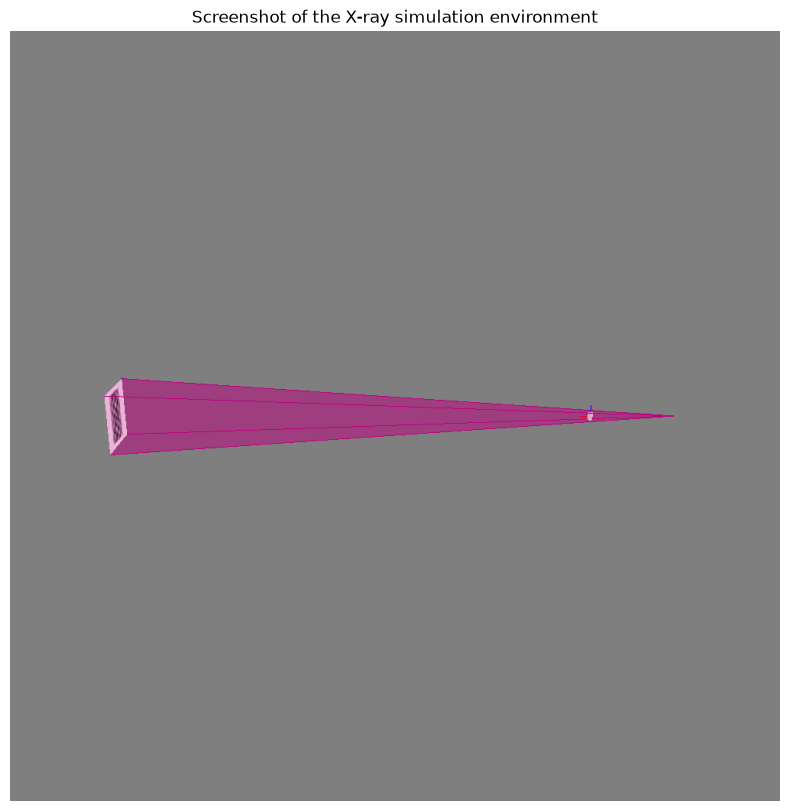

In [14]:
gvxr.setWindowSize(1000, 1000)
gvxr.setCameraPosition(35.0, 150.0, 50.0, "cm")
gvxr.setCameraReferencePoint(35.0, 0.0, 0.0, "cm")
gvxr.setCameraUp(0, 0, 1)  # keep +z as screen-up
gvxr.displayScene()

screenshot = gvxr.takeScreenshot()
# Display it using Matplotlib
plt.figure(figsize=(10, 10))
plt.imshow(screenshot)
plt.title("Screenshot of the X-ray simulation environment")
plt.axis("off")
plt.show()


Unattenuated photons per pixel: 717


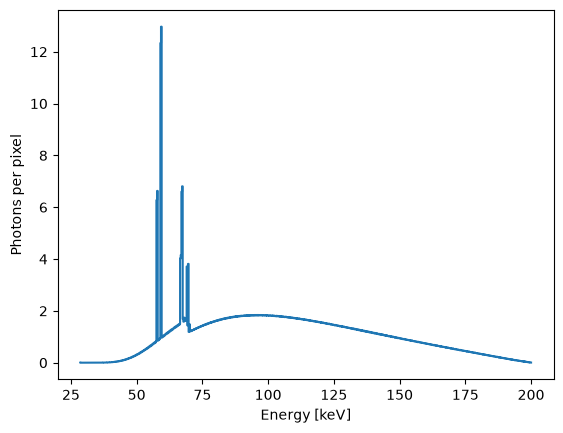

In [15]:
counts_per_bin = np.array(gvxr.getPhotonCountsPerPixelAtSDD())
energies = np.array(gvxr.getEnergyBins("keV"))
print(f"Unattenuated photons per pixel: {counts_per_bin.sum():.0f}")

plt.step(energies, counts_per_bin, where="mid")
plt.xlabel("Energy [keV]")
plt.ylabel("Photons per pixel")
plt.show()


In [16]:
# NOTE: This cell is very slow to run and it will look like it hangs,
# at least in VSCode.
# You can check progress by the number of TIFF files in the output
unit = "mm"
number_of_projections = np.ceil(np.pi / 2 * 512)
rotation_centre_in_mm = gvxr.getNodeAndChildrenBoundingBoxCentre("root", unit)
rotation_axis = gvxr.getDetectorUpVector()

gvxr.computeCTAcquisition(
    str(data_dir / "projections"),
    "",  # The path where the screenshots will be saved
    number_of_projections,  # The total number of projections to simulate
    0,  # The rotation angle corresponding to the first projection
    False,  # A boolean flag to include or exclude the last angle
    360,  # The rotation angle corresponding to the last projection
    50,  # The number of white images used to perform the flat-field correction
    *rotation_centre_in_mm,  # The location of the rotation centre
    unit,  # The corresponding unit of length
    *rotation_axis,  # The rotation axis
)

In [17]:
# Save metadata for CIL
from gvxrPython3 import gvxr2json

gvxr2json.saveJSON(str(data_dir / "projections" / "simulation.json"))


mAs 0.0020000000949949026 kVp 200.0
